## Problema - Organización y búsqueda de productos en una tienda

**Instrucción:** completa esta plantilla con tu diseño y desarrollo. Evita incluir soluciones generadas automáticamente.



In [1]:

# @title Ingrese datos
nombre_estudiante = "Jeronimo Urrego Morales, Daniel Felipe Cardenas Romero, Andres Felipe Rubio Arango" # @param {"type":"string"}
carnet = None # @param {"type":"integer"} 1000111199, 1000110894, 1000045645 respectivamente


## 1) Descripción del problema **[1 pts]**

Una tienda necesita optimizar el tiempo de consulta de los productos de su inventario, ya que actualmente realiza una búsqueda secuencial recorriendo toda la lista, lo cual resulta poco eficiente. Para solucionar esto, se requiere implementar una Tabla Hash donde la llave de acceso sea el código numérico del producto. Esta estructura permitirá calcular matemáticamente la posición en memoria, reduciendo el tiempo de búsqueda, inserción y eliminación, y manejando las colisiones mediante listas enlazadas (encadenamiento)

## 2) Requerimientos **[2 pts]**

### Requerimientos Funcionales:
- El sistema debe solicitar al usuario el tamaño m para inicializar la tabla vacía.
- El cálculo de la posición debe realizarse estrictamente con la función h(código) = código % m.
- El sistema debe manejar las colisiones de índices utilizando encadenamiento.
- El sistema debe impedir el registro de dos productos con el mismo código.
- Las funciones de inserción, búsqueda y eliminación deben calcular primero la posición con la función hash para acceder directamente a la ubicación.
- El sistema debe permitir la actualización de la cantidad disponible de un producto específico.
- El sistema debe mostrar visualmente el estado completo de la tabla, evidenciando las colisiones en una misma posición.

### Requerimientos No Funcionales:
- La Tabla Hash debe ser desarrollada manualmente utilizando las estructuras base del lenguaje, sin librerías de diccionarios o mapas prefabricados.
- La interfaz de usuario debe operar por consola de comandos (CLI) a través de un menú interactivo.
- El sistema debe contar con validación de tipos de datos para evitar bloqueos ante ingresos no numéricos.



## 3) Historias de usuario **[2 pts]**
### HU1: Registro de Productos:
Como administrador de inventario, quiero registrar un nuevo producto utilizando su código numérico para agregarlo al catálogo.
#### Criterios de Aceptación:
- El sistema calcula el índice correctamente usando código % m.
- Si el código ya existe, el sistema bloquea la inserción y muestra un error.
- Si hay otro producto en el mismo índice, se agrega al final de la cadena sin borrar el anterior.

### HU2: Búsqueda Eficiente:
Como vendedor, quiero buscar un producto ingresando su código para verificar rápidamente su precio y cantidad disponible.
#### Criterios de Aceptación:
- El sistema no recorre toda la tabla, sino que salta directo al índice generado por la función hash.  
- Si el producto existe en esa posición, muestra sus datos.  
- Si no existe, notifica que no está registrado.

### HU3: Visualización de Estructura:
Como auditor del sistema, quiero visualizar la tabla completa para verificar el correcto funcionamiento del encadenamiento y la distribución.
#### Criterios de Aceptación:
- Se imprimen todas las posiciones de la 0 a la m-1.
- Las posiciones sin productos se marcan como "Vacío".
- Las posiciones con colisiones muestran los productos separados por un indicador visual (ej. ->).

## 4) Diagramas de flujo **[5 pts]**

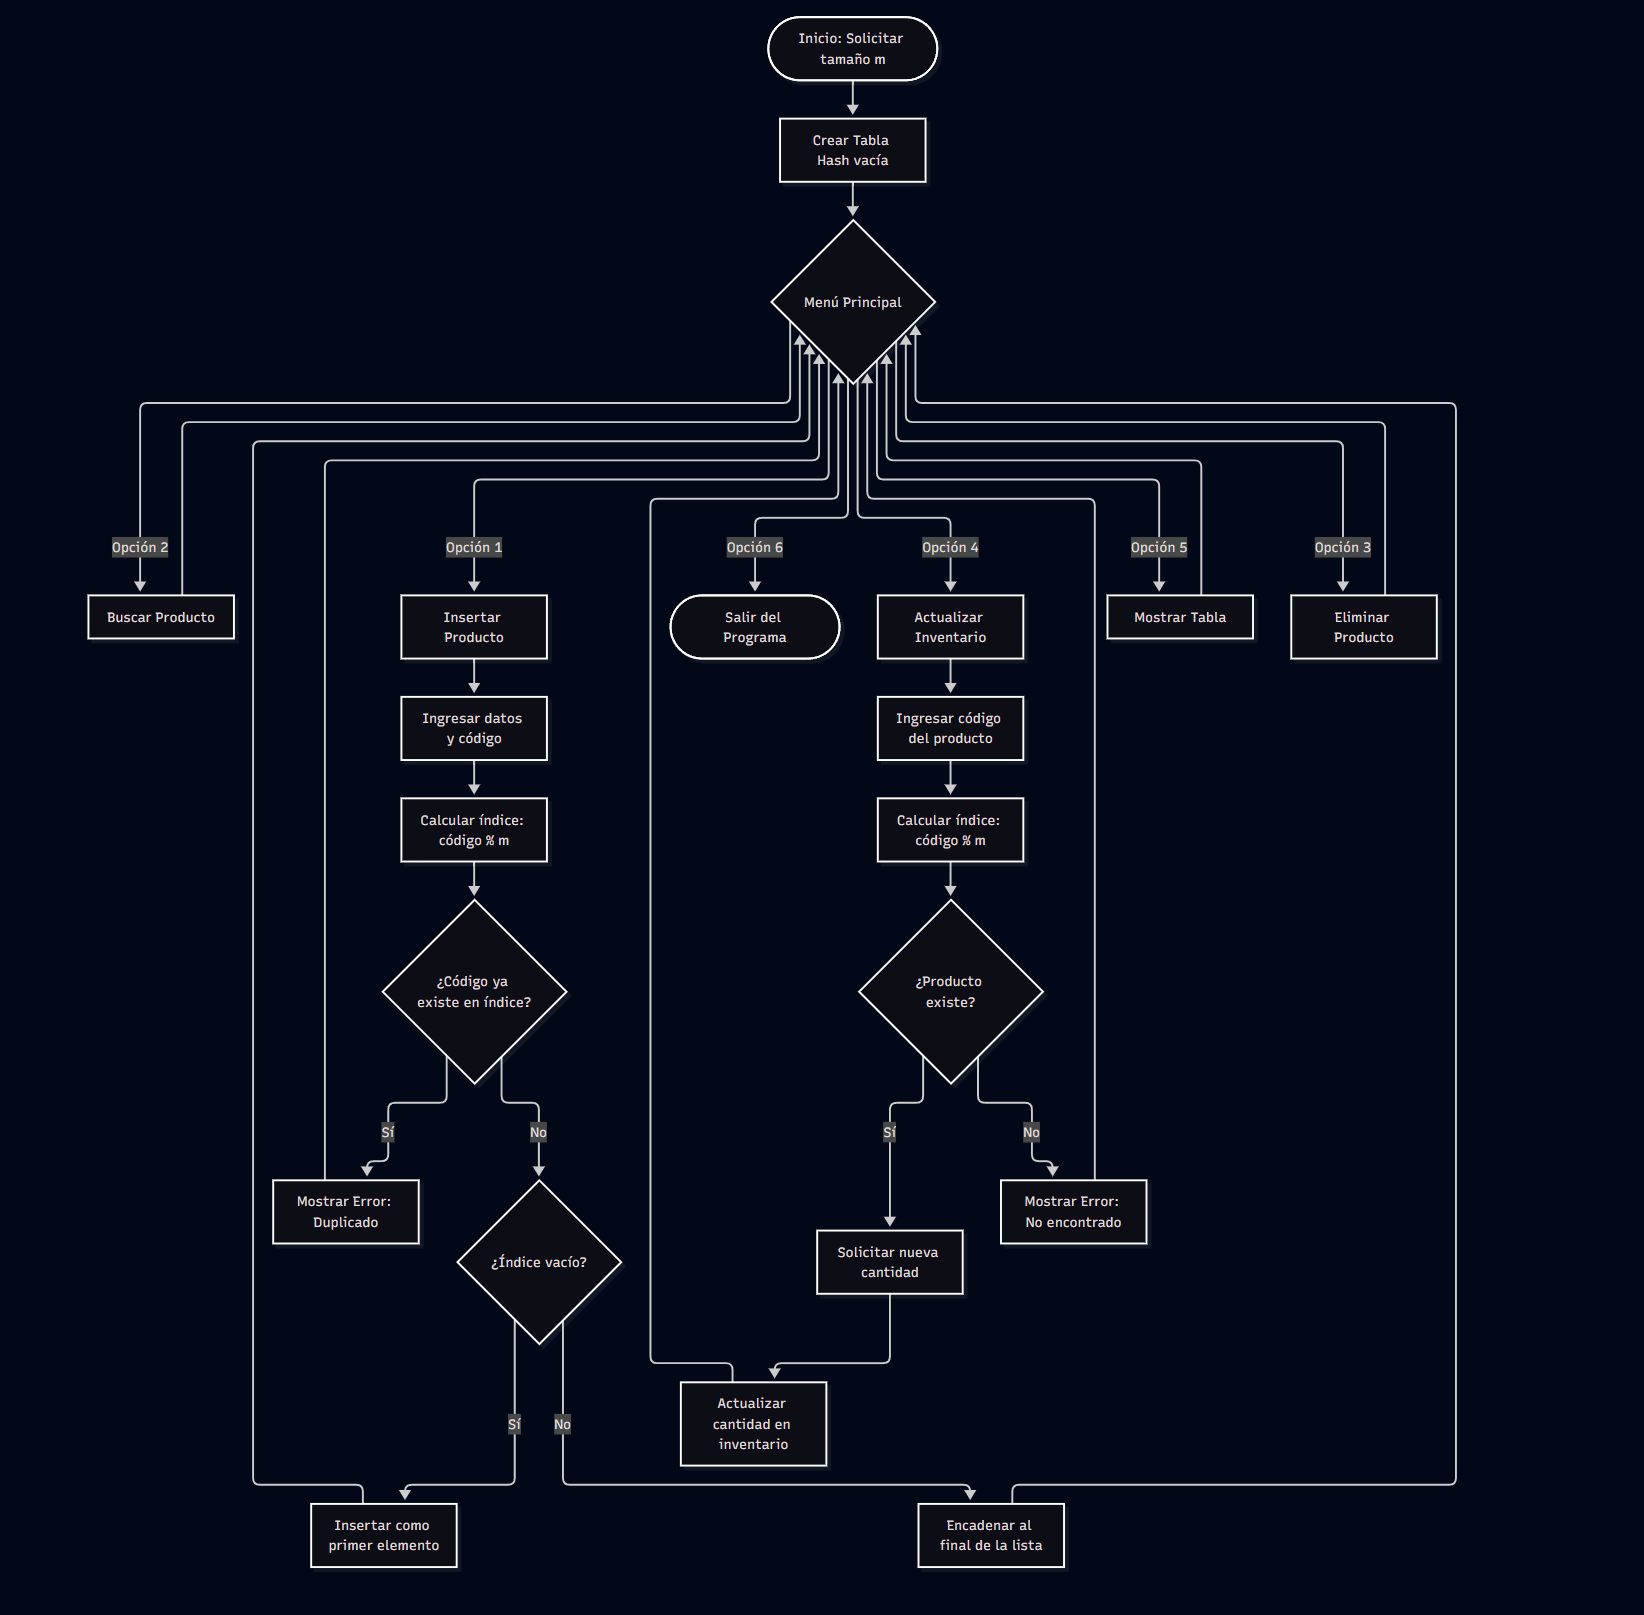

### Descripcion:

El diagrama representa el ciclo de ejecución lógico del sistema de inventario. Comienza con la etapa de inicialización, donde el sistema solicita el tamaño m y construye la estructura de la Tabla Hash vacía. A continuación, el flujo entra al **Menú Principal**, que actúa como un ciclo continuo que redirige a las distintas operaciones.

Se desglosan internamente dos subprocesos críticos:

* **Flujo de Inserción (Opción 1):** Tras ingresar los datos, el sistema calcula la posición usando la función hash (código % m). Luego, verifica que el código no esté duplicado. Según el estado de la posición calculada, el producto se inserta como el primer elemento (si está vacío) o se añade al final de la lista existente, aplicando la regla de encadenamiento para resolver la colisión.
* **Flujo de Actualización (Opción 4):** Se ingresa el código a modificar, se calcula su índice y se busca en esa posición. Si el producto se encuentra, el sistema pide la nueva cantidad y actualiza el inventario; si no, muestra un error de que no fue encontrado.

Todas las opciones operativas (búsqueda, eliminación y visualización incluidas) convergen de vuelta al **Menú Principal** tras finalizar su tarea. El programa se mantiene en este ciclo hasta que el usuario selecciona la opción **Salir del Programa**, rompiendo el bucle y finalizando la ejecución.



### 5) Análisis de complejidad **[15 pts]**

### Justificación:
La eficiencia de una Tabla Hash radica en la función matemática que transforma la llave en un índice directo en memoria. El cálculo del módulo (código % m) es una operación aritmética simple de tiempo constante. Sin embargo, debido al manejo de colisiones por encadenamiento, el tiempo real dependerá de cuántos elementos terminan agrupados en la misma posición (longitud de la cadena subyacente).   

### Función T(n):

Sea n el número de elementos guardados en la misma posición de la tabla (longitud de la cadena).
Cálculo del hash: c1 (Constante)
Acceso al índice: c2 (Constante)
Recorrido de la cadena para buscar/insertar al final: c3 * n

T(n) = (c1 + c2) + c3 * n

#### Mejor Caso: O(1)
Ocurre cuando no hay colisiones en el índice calculado. El producto se inserta, encuentra o elimina instantáneamente en el primer nodo de esa posición.

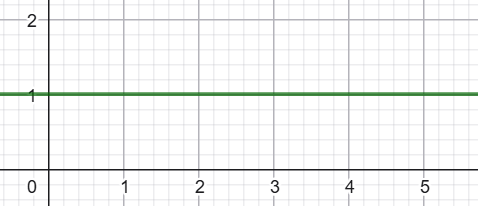

#### Peor Caso: O(n)
Ocurre cuando todos los productos ingresados en el sistema generan exactamente el mismo índice (por ejemplo, todos los códigos son múltiplos de m). La Tabla Hash degenera en una única lista enlazada tradicional, perdiendo toda su eficiencia al tener que recorrer n elementos.

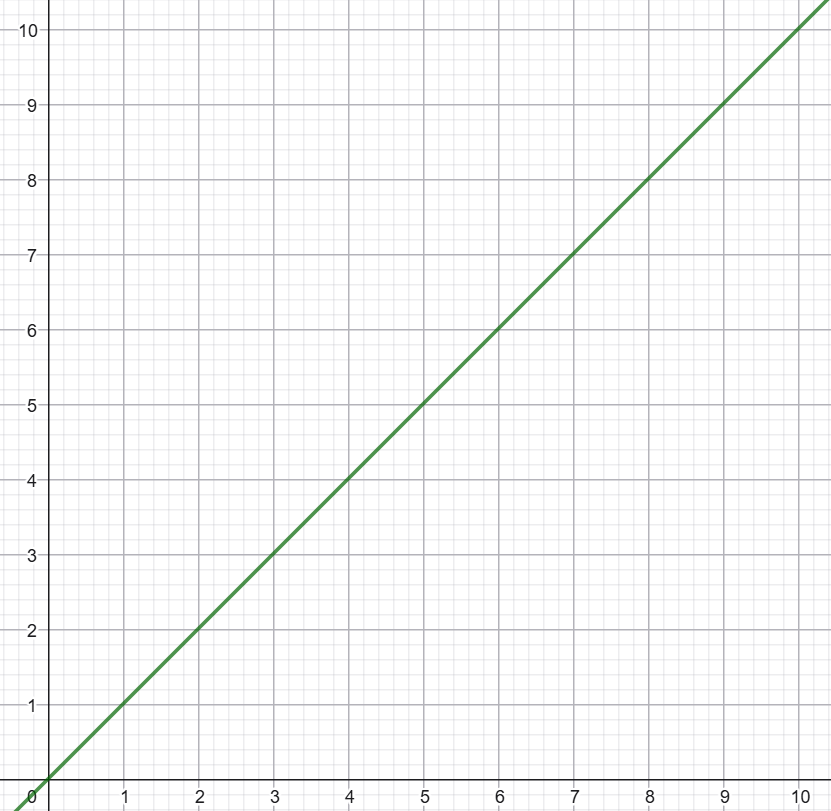




## 6) Código funcional **[15 pts]**
Incluye tu implementación completa.

No pegues código incompleto; debe ser ejecutable.


In [2]:
def crear_tabla(m):
    """
    Crea una tabla hash vacía de tamaño m.
    Se utiliza una lista de listas para manejar el encadenamiento.
    """
    return [[] for rep in range(m)]

def funcion_hash(codigo, m):
    """Calcula el índice usando la función hash del módulo h(código) = código % m."""
    return codigo % m

def existe_codigo(tabla, m, codigo):
    """Verifica si el código ya existe en la tabla para evitar duplicados."""
    indice = funcion_hash(codigo, m)
    for producto in tabla[indice]:
        if producto['codigo'] == codigo:
            return True
    return False

def insertar_productos(tabla, m):
    """Inserta n productos en la tabla manejando colisiones por encadenamiento."""
    try:
        n = int(input("¿Cuántos productos desea registrar?: "))
        for rep in range(n):
            codigo = int(input("\nCódigo: "))
            if existe_codigo(tabla, m, codigo):
                print("Error: Este código ya está registrado. No se permiten duplicados.")
                continue
            
            nombre = input("Nombre: ")
            precio = float(input("Precio: "))
            cantidad = int(input("Cantidad: "))

            producto = {
                'codigo': codigo,
                'nombre': nombre,
                'precio': precio,
                'cantidad': cantidad
            }
            
            indice = funcion_hash(codigo, m)
            tabla[indice].append(producto) # Encadenamiento: se agrega al final de la lista en esa posición
            print(f"Producto '{nombre}' almacenado correctamente en la posición {indice}.")
            
    except ValueError:
        print("Error: Entrada inválida. Verifique que los datos numéricos sean correctos.")

def buscar_producto(tabla, m):
    """Busca un producto calculando su posición directa sin recorrer toda la tabla."""
    try:
        codigo = int(input("Ingrese el código del producto a buscar: "))
        indice = funcion_hash(codigo, m)
        
        for producto in tabla[indice]: #Busca en la posicion unicamente
            if producto['codigo'] == codigo:
                print(f"Producto encontrado - Código: {producto['codigo']} Nombre: {producto['nombre']} Precio: ${producto['precio']} Cantidad disponible: {producto['cantidad']}")
                return
                
        print("El producto no está registrado.")
    except ValueError:
        print("Error: Ingrese un número entero válido.")

def eliminar_producto(tabla, m):
    """Elimina un producto específico utilizando su código y la función hash."""
    try:
        codigo = int(input("Código del producto que desea eliminar: "))
        indice = funcion_hash(codigo, m)
        
        for rep, producto in enumerate(tabla[indice]):
            if producto['codigo'] == codigo:
                del tabla[indice][rep]
                print(f"El producto con código {codigo} ha sido eliminado de la posición {indice}.")
                return
                
        print("No se encontró el producto.")
    except ValueError:
        print("Error: Ingrese un número entero válido.")

def actualizar_inventario(tabla, m):
    """Actualiza la cantidad de un producto por código."""
    try:
        codigo = int(input("Código del producto a actualizar: "))
        indice = funcion_hash(codigo, m)
        
        for producto in tabla[indice]:
            if producto['codigo'] == codigo:
                print(f"Producto: {producto['nombre']} | Cantidad actual: {producto['cantidad']}")
                nueva_cantidad = int(input("Nueva cantidad: "))
                producto['cantidad'] = nueva_cantidad
                print(f"Inventario actualizado correctamente. {producto['nombre']} - {nueva_cantidad} unidades")
                return
                
        print("No se encontró el producto.")
    except ValueError:
        print("Error: Ingrese valores numéricos válidos.")

def mostrar_tabla(tabla):
    """Muestra el contenido completo de la estructura y evidencia las colisiones."""
    print("\n============================== TABLA HASH ==============================")
    for rep, cadena in enumerate(tabla):
        if not cadena:
            print(f"{rep} -> Vacío")
        else:
            # Formatea los productos de la lista en esa posición separándolos por " -> "
            str_cadena = " -> ".join([f"{p['codigo']} - {p['nombre']}" for p in cadena])
            print(f"{rep} -> {str_cadena}")
    print("========================================================================")

def main():
    print("--- Sistema Inventario de Productos ---")
    try:
        m = int(input("Ingrese el tamaño de la tabla hash (m): "))
        if m <= 0:
            print("El tamaño debe ser mayor a 0.")
            return
    except ValueError:
        print("Debe ingresar un número entero válido.")
        return

    tabla = crear_tabla(m)
    print("Tabla Hash inicializada con éxito.\n")

    while True:
        print("\n--- MENÚ DE INVENTARIO ---")
        print("1. Registrar/Insertar productos")
        print("2. Buscar un producto")
        print("3. Eliminar un producto")
        print("4. Actualizar inventario")
        print("5. Mostrar la Tabla Hash")
        print("6. Salir")

        opcion = input("Seleccione una opción (1-6): ")

        if opcion == '1':
            insertar_productos(tabla, m)
        elif opcion == '2':
            buscar_producto(tabla, m)
        elif opcion == '3':
            eliminar_producto(tabla, m)
        elif opcion == '4':
            actualizar_inventario(tabla, m)
        elif opcion == '5':
            mostrar_tabla(tabla)
        elif opcion == '6':
            print("Cerrando el sistema de inventario...")
            break
        else:
            print("Opción no válida. Por favor intente de nuevo.")
main()

--- Sistema Inventario de Productos ---
Tabla Hash inicializada con éxito.


--- MENÚ DE INVENTARIO ---
1. Registrar/Insertar productos
2. Buscar un producto
3. Eliminar un producto
4. Actualizar inventario
5. Mostrar la Tabla Hash
6. Salir
Producto 'Arroz' almacenado correctamente en la posición 2.
Producto 'Nutella' almacenado correctamente en la posición 0.
Error: Entrada inválida. Verifique que los datos numéricos sean correctos.

--- MENÚ DE INVENTARIO ---
1. Registrar/Insertar productos
2. Buscar un producto
3. Eliminar un producto
4. Actualizar inventario
5. Mostrar la Tabla Hash
6. Salir
Producto 'Pollo' almacenado correctamente en la posición 1.
Producto 'Lechuga' almacenado correctamente en la posición 2.
Producto 'Leche' almacenado correctamente en la posición 0.
Producto 'CocaCola' almacenado correctamente en la posición 1.

--- MENÚ DE INVENTARIO ---
1. Registrar/Insertar productos
2. Buscar un producto
3. Eliminar un producto
4. Actualizar inventario
5. Mostrar la Tabla H

## 7) Tests aplicados **[15 pts]**

In [ ]:
def pruebas_automaticas():
    """Bloque de pruebas para verificar la lógica interna de la Tabla Hash"""
    print("\n--- INICIANDO PRUEBAS AUTOMÁTICAS ---")
    
    # 1. Probar la creación de la tabla
    m = 7
    tabla = crear_tabla(m)
    assert len(tabla) == 7, "Error: La tabla no tiene el tamaño correcto."
    
    # 2. Probar la función hash
    assert funcion_hash(101, m) == 3, "Error: El cálculo de la función hash es incorrecto."
    assert funcion_hash(108, m) == 3, "Error: El cálculo de la función hash es incorrecto."
    
    # 3. Probar inserción directa y encadenamiento (Colisión en índice 3)
    producto_1 = {'codigo': 101, 'nombre': 'Arroz', 'precio': 4500, 'cantidad': 20}
    producto_2 = {'codigo': 108, 'nombre': 'Huevos', 'precio': 16000, 'cantidad': 12}
    
    tabla[3].append(producto_1)
    tabla[3].append(producto_2)
    
    # Verificamos que ambos estén en la misma posición (encadenamiento exitoso)
    assert len(tabla[3]) == 2, "Error: El encadenamiento falló, no hay 2 productos en la posición 3."
    assert tabla[3][0]['nombre'] == 'Arroz', "Error: El primer producto no es Arroz."
    assert tabla[3][1]['nombre'] == 'Huevos', "Error: El segundo producto no es Huevos."
    
    # 4. Probar la función existe_codigo
    assert existe_codigo(tabla, m, 101) == True, "Error: No detectó un código que ya existe."
    assert existe_codigo(tabla, m, 999) == False, "Error: Detectó como existente un código falso."
    
    print("¡Todas las pruebas pasaron con éxito! La lógica de la tabla funciona correctamente.")
    print("-------------------------------------\n")

pruebas_automaticas()
    


--- INICIANDO PRUEBAS AUTOMÁTICAS ---
¡Todas las pruebas pasaron con éxito! La lógica de la tabla funciona correctamente.
-------------------------------------

